In [1]:
# Import Libraries and Euler Method Solver
import numpy as np 
import matplotlib.pyplot as plt 

steps = 1000
nsteps = 1000

def euler_newton(force, times, x0, v0, m,dt):
    # Create arrays for x and v 
    x = []
    v = []

    # Store the initial conditions for the first elements 
    x.append(x0)
    v.append(v0)

    # For loop
    for i in range(steps - 1):

        a = force(times[i], x[i], v[i], k, b) / m
        v.append(v[i] + a*dt)
        x.append(x[i] + v[i+1]*dt)

    return x, v
    
stop=50
times,dt = np.linspace(0, stop, nsteps,retstep=True)

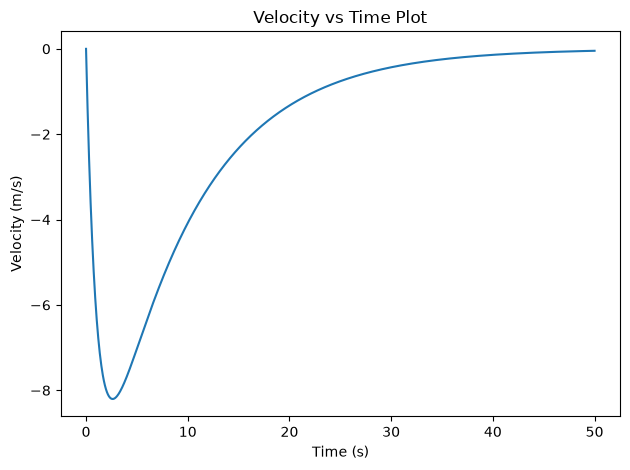

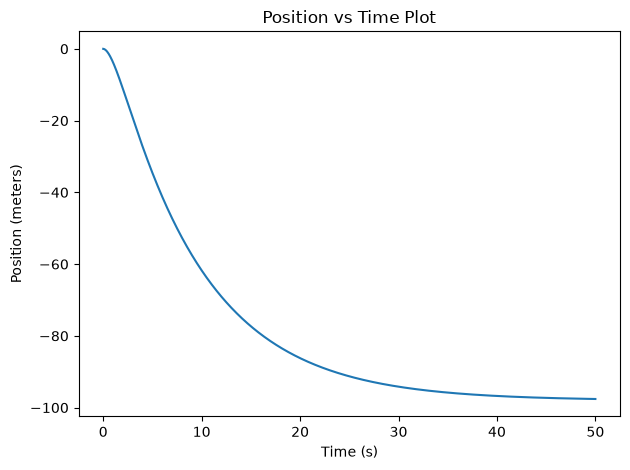

In [2]:
# Question 1: Euler's Method and Restorative Spring Force

# Declare Restorative Spring Force 
def rForce(t, x, v, k, b):
    return (-k*x) + (-m*9.8 - b*v)

# Initialize Constants 
m = 10
k = 1
b = 10
x0 = 0
v0 = 0

# Call to Euler 
euler = euler_newton(rForce, times, x0, v0, m, dt)

# Plot Velocity vs Time 
plt.plot(times, euler[1])
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("Velocity vs Time Plot")
plt.tight_layout()
plt.show()

# Plot Position vs Time
plt.plot(times, euler[0])
plt.xlabel("Time (s)")
plt.ylabel("Position (meters)")
plt.title("Position vs Time Plot")
plt.tight_layout()
plt.show()

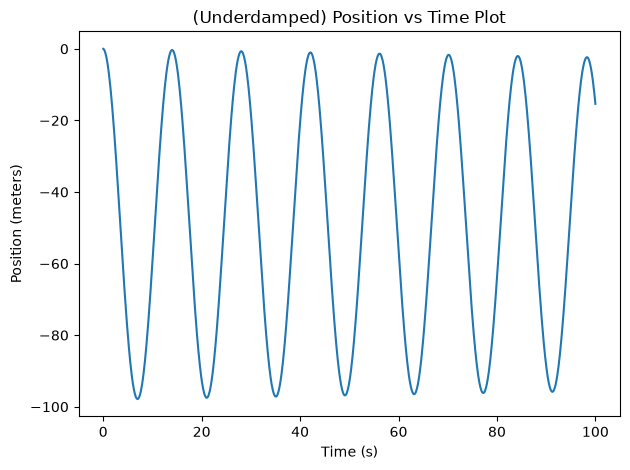

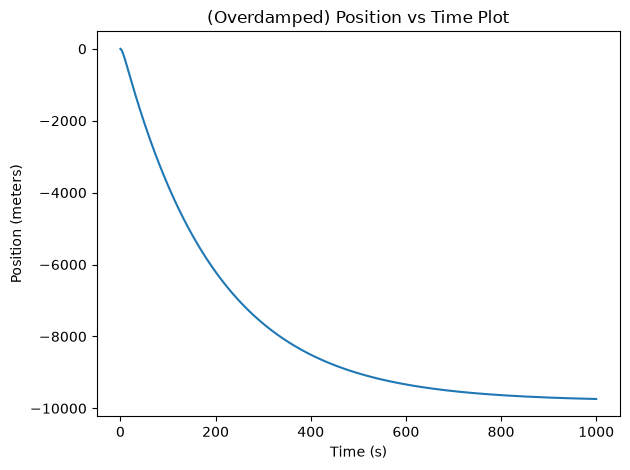

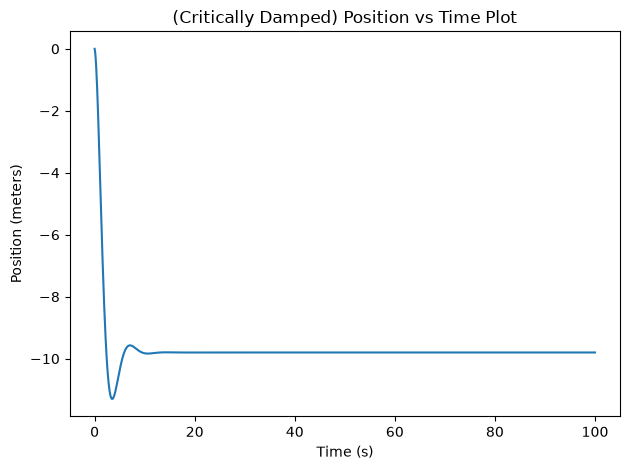

In [3]:
# Question 2: Testing the Various Damped Cases

# a. Underdamped Oscillations 
b = 1
m = 1000
k = 200
x0 = 0
v0 = 0


stop=100
times,dt = np.linspace(0, stop, nsteps,retstep=True)

euler = euler_newton(rForce, times, x0, v0, m, dt)

plt.plot(times, euler[0])
plt.xlabel("Time (s)")
plt.ylabel("Position (meters)")
plt.title("(Underdamped) Position vs Time Plot")
plt.tight_layout()
plt.show()

# b. Overdamped Oscillations
b = 200
m = 1000
k = 1
x0 = 0
v0 = 0


stop=1000
times,dt = np.linspace(0, stop, nsteps,retstep=True)


euler = euler_newton(rForce, times, x0, v0, m, dt)

plt.plot(times, euler[0])
plt.xlabel("Time (s)")
plt.ylabel("Position (meters)")
plt.title("(Overdamped) Position vs Time Plot")
plt.tight_layout()
plt.show()

# c. Critically Damped Oscillations
b = 1 
m = 1
k = 1
x0 = 0 
v0 = 0


stop=100
times,dt = np.linspace(0, stop, nsteps,retstep=True)

euler = euler_newton(rForce, times, x0, v0, m, dt)

plt.plot(times, euler[0])
plt.xlabel("Time (s)")
plt.ylabel("Position (meters)")
plt.title("(Critically Damped) Position vs Time Plot")
plt.tight_layout()
plt.show()

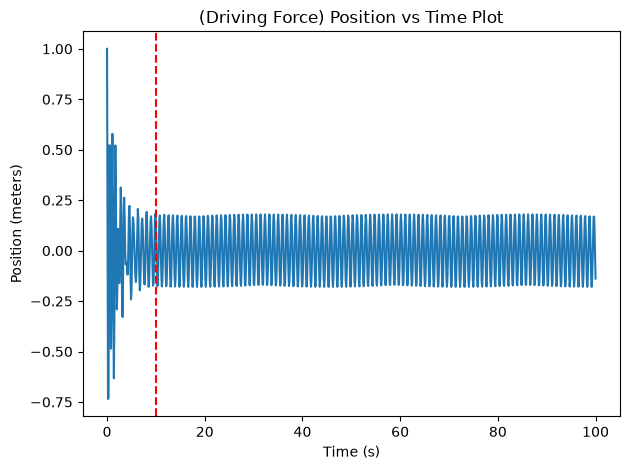

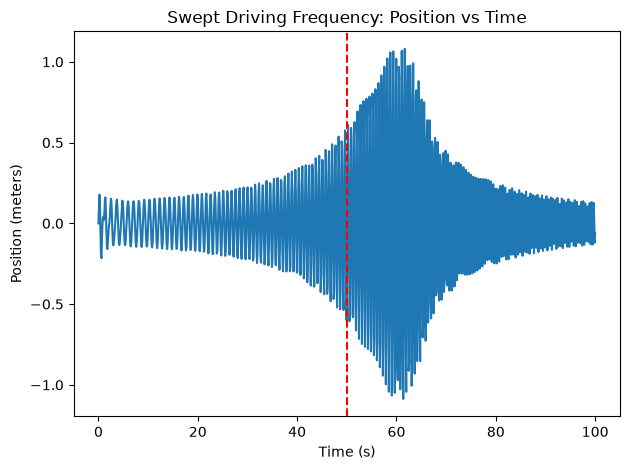

In [4]:
# Question 3: Consider the Driving Force Function

# a. Plot the GLO

# Define Driving Force 
def drivingForce(t, x, v, k, b, f0, wd):
    return -k*x - b*v + f0*np.cos(wd*t)

# Initial Conditions 
b = 1
m = 1
k = 100
x0 = 1 
v0 = 0
f0 = 10
wd = 7

stop=100
times,dt = np.linspace(0, stop, nsteps,retstep=True)

# Euler Solution
euler = euler_newton(lambda t, x, v, k, b: drivingForce(t, x, v, k, b, f0, wd),
                     times, x0, v0, m, dt)

# Plot Euler Solution and Transient Line
tau = 2*m/b
transient = 5*tau

plt.plot(times, euler[0])
plt.axvline(transient, color='r', ls='--', label="Transient Solution")
plt.xlabel("Time (s)")
plt.ylabel("Position (meters)")
plt.title("(Driving Force) Position vs Time Plot")
plt.tight_layout()
plt.show()

# NOTE: The red line represents when the transient solution decays and the oscillations stabilize
 
# b. Sweeping Across Frequencies

# Define the Sweeping Force
def sweepForce(t, x, v, k, b, f0, w_start, alpha):
    phase = w_start*t + 0.5*alpha*t**2
    return -k*x - b*v + f0*np.cos(phase)

# Initial Conditions
b = 1
m = 1
k = 100
x0 = 0
v0 = 0
f0 - 0
w0 = np.sqrt(k/m)
w_start = 5
w_end = 15
stop = 100
alpha = (w_end - w_start)/stop


times, dt = np.linspace(0, stop, nsteps, retstep=True)

# Solve It Via Euler
euler = euler_newton(lambda t, x, v, k, b: sweepForce(t, x, v, k, b, f0, w_start, alpha),
                     times, x0, v0, m, dt)

# Plot It
t_res = (w0 - w_start)/alpha

plt.plot(times, euler[0])
plt.axvline(t_res, color='r', ls='--')
plt.xlabel("Time (s)")
plt.ylabel("Position (meters)")
plt.title("Swept Driving Frequency: Position vs Time")
plt.tight_layout()
plt.show()

# NOTE: The red line here represents the time when the driving frequency equals the natural frequency.

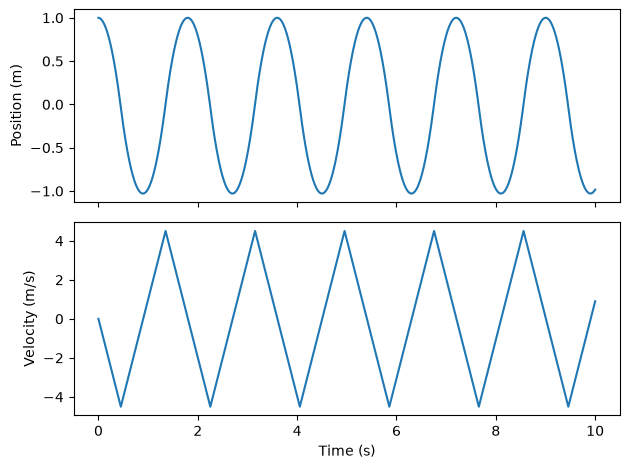

In [11]:
# Question 4: Georgi Forcing Function

# Define the Forcing Function
def signForce(t,x,v,k,b, f0):
    return -f0*np.sign(x) # Note that .sign() handles the piecewise definition

# Initial Conditions
m = 1
f0 = 10
x0 = 1
v0 = 0
stop = 10

times, dt = np.linspace(0, stop, nsteps, retstep=True)

# Get Euler Solution
euler = euler_newton(lambda t, x, v, k, b: signForce(t, x, v, k, b, f0), times, x0, v0, m, dt)

# Plot the Solution 
period = 4*np.sqrt(2*m*x0/f0)

fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(times, euler[0])
ax[0].set_ylabel("Position (m)")
ax[1].plot(times, euler[1])
ax[1].set_ylabel("Velocity (m/s)")
ax[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

# Explanation 
# We see this motion because if position is oscillating, then our velocity will be a series of linear lines going up and down (creating a "V" graph)
# The force always points back to the origin, so the particle is always pulled back and never escapes. No drag and energy conserved means we get the same height each time.
# The free part of the graph is vt (what the particle would do with no force) and the forced part is (f0/2m)*t^2, the deviation the constant force adds.

# Scenario With Similar Motion
# If you throw a bouncy ball on the floor, its position and velocity with relation to time would oscillate very similarly to what we see presented on the graphs.
